# FTIR EC follow-up: questions from the 9 Oct 2026 meeting with Ann

Four questions came up while walking through the gallery's Meeting tab. Everything here reads saved
outputs of the completed rank-70 runs; nothing is refitted except the Addis band areas in section 4.

1. **Can IMPROVE predict itself?** If a calibration cohort predicts its own held-out IMPROVE filters well
   but not Addis, the problem is in the Addis samples (or their transfer), not the calibration set.
2. **Is it the wavenumber range?** In the meeting, VIBES cut at 1425 cm⁻¹ looked like spline for Kiremt.
3. **Mass, not concentration.** IMPROVE samples ~4x more air than SPARTAN, so concentration axes exaggerate
   how far Addis sits from IMPROVE.
4. **The extra hump near 1000-1300 cm⁻¹ in Addis.** Sulfate, silicate, or something else?

Conventions (docs/naming-conventions.md): **calibration set** = IMPROVE filters a model is built on;
**cross-validation** = IMPROVE sites held out of the calibration set; **test set** = the Addis filters.
Regression is Deming at MAC 10. "Spline baseline" = AIRSpec; "VIBES" = the completed rank-70 full-range
correction; "VIBES cut" = the same correction with only 4000-1425 cm⁻¹ used for prediction.

In [1]:
import sys
# For notebooks inside research/ftir_hips_chem/:
sys.path.insert(0, './scripts')

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
from scipy.stats import spearmanr

from config import MAC_VALUE
from plotting import PlotConfig
from vibes_current import MIGRATION, load_context
from data_matching import load_filter_data

PlotConfig.set(sites='Addis_Ababa', layout='individual', show_stats=True, show_1to1=True)
T = MIGRATION / 'meeting'                      # completed rank-70 meeting run
FIG = Path('output/plots/ann_followup_20261009')
FIG.mkdir(parents=True, exist_ok=True)

rep = pd.read_csv(T / 'repeated_splits.csv')
stats = pd.read_csv(T / 'panel_stats.csv')
fits = pd.read_csv(T / 'fits.csv')
pool_pts = pd.read_csv(T / 'pool_test_predictions.csv')   # workflows/run_pool_test_points_20261009.py
refs = pd.read_csv(T / 'improve_references.csv')
addis_eval = pd.read_csv(T / 'addis_evaluation.csv')

SEASONS = ['Dry (Oct-Feb)', 'Belg (Mar-May)', 'Kiremt (Jun-Sep)']
GROUPS = ['All Addis'] + SEASONS
METHODS = {'AIRSpec': 'Spline', 'VIBES-full-r70': 'VIBES', 'VIBES-full-cut-r70': 'VIBES cut'}
SEASON_COLORS = {'Dry (Oct-Feb)': '#E67E22', 'Belg (Mar-May)': '#27AE60', 'Kiremt (Jun-Sep)': '#3498DB', 'All Addis': '#5b6470'}
print(f'{len(rep)} repeated splits, {len(stats)} panel statistics, {len(pool_pts)} held-out IMPROVE predictions')

1200 repeated splits, 488 panel statistics, 13215 held-out IMPROVE predictions


## 1. Can IMPROVE predict itself?

**Seasonal analog calibrations.** Each season's 500 IMPROVE analogs, 100 site-grouped splits: about 20 % of
the analogs are held out by whole site, k is chosen on the rest, and the same calibration predicts both
the held-out IMPROVE filters and the season's Addis filters. Medians over the 100 splits.

In [2]:
cols = {'k': 'k', 'TOR_test_R2': 'CV TOR R²', 'ftir_vs_tor_slope': 'CV FTIR vs TOR slope',
        'ftir_vs_tor_intercept': 'CV FTIR vs TOR intercept', 'ftir_vs_fabs_slope': 'CV FTIR vs HIPS slope',
        'ftir_vs_fabs_intercept': 'CV FTIR vs HIPS intercept', 'addis_slope': 'Addis slope',
        'addis_intercept': 'Addis intercept', 'addis_R2': 'Addis R²'}
self_pred = (rep.groupby(['method', 'group'])[list(cols)].median().rename(columns=cols)
             .rename(index=METHODS, level=0).reindex(GROUPS, level=1))
self_pred.to_csv(FIG / 'self_prediction_seasonal.csv')
display(self_pred.round(2))

k  CV TOR R²  CV FTIR vs TOR slope  \
method    group                                                     
Spline    All Addis         17.0       0.81                  0.80   
          Dry (Oct-Feb)      9.0       0.46                  0.52   
          Belg (Mar-May)     8.0       0.56                  0.67   
          Kiremt (Jun-Sep)  12.5       0.66                  0.78   
VIBES cut All Addis         19.0       0.77                  0.85   
          Dry (Oct-Feb)     11.0       0.76                  0.71   
          Belg (Mar-May)    18.0       0.73                  0.79   
          Kiremt (Jun-Sep)  18.0       0.73                  0.78   
VIBES     All Addis          8.0       0.78                  0.77   
          Dry (Oct-Feb)     22.0       0.86                  0.91   
          Belg (Mar-May)     7.0       0.75                  0.79   
          Kiremt (Jun-Sep)   8.0       0.62                  0.64   

                            CV FTIR vs TOR intercept  CV FTIR vs HIPS slope  \
method    group                                                               
Spline    All Addis                             0.04                   0.83   
          Dry (Oct-Feb)                         0.06                   0.38   
          Belg (Mar-May)                        0.10                   0.67   
          Kiremt (Jun-Sep)                      0.13                   0.88   
VIBES cut All Addis                             0.05                   1.03   
          Dry (Oct-Feb)                         0.03                   0.71   
          Belg (Mar-May)                        0.08                   1.00   
          Kiremt (Jun-Sep)                      0.11                   1.01   
VIBES     All Addis                             0.11                   0.96   
          Dry (Oct-Feb)                         0.02                   0.91   
          Belg (Mar-May)                        0.12                   0.93   
          Kiremt (Jun-Sep)                      0.21                   0.81   

                            CV FTIR vs HIPS intercept  Addis slope  \
method    group                                                      
Spline    All Addis                              0.01         0.71   
          Dry (Oct-Feb)                          0.07         0.29   
          Belg (Mar-May)                         0.09         0.45   
          Kiremt (Jun-Sep)                       0.10         0.86   
VIBES cut All Addis                             -0.00         1.88   
          Dry (Oct-Feb)                          0.02         1.23   
          Belg (Mar-May)                         0.01         1.44   
          Kiremt (Jun-Sep)                       0.04         2.06   
VIBES     All Addis                              0.04         2.19   
          Dry (Oct-Feb)                          0.00         1.81   
          Belg (Mar-May)                         0.07         1.37   
          Kiremt (Jun-Sep)                       0.17         2.21   

                            Addis intercept  Addis R²  
method    group                                        
Spline    All Addis                   -1.50      0.67  
          Dry (Oct-Feb)               -0.06      0.46  
          Belg (Mar-May)              -0.11      0.46  
          Kiremt (Jun-Sep)            -0.66      0.57  
VIBES cut All Addis                   -5.15      0.65  
          Dry (Oct-Feb)               -2.91      0.49  
          Belg (Mar-May)              -2.72      0.60  
          Kiremt (Jun-Sep)            -5.22      0.73  
VIBES     All Addis                   -6.08      0.72  
          Dry (Oct-Feb)               -4.23      0.47  
          Belg (Mar-May)              -2.56      0.59  
          Kiremt (Jun-Sep)            -6.21      0.77

**The all-IMPROVE models** (the current-model reading: lot 251, and both lots). Here the held-out split is
the whole IMPROVE network, so we can compare three populations under one calibration: every held-out
IMPROVE filter, the held-out filters that are also a season's analogs, and Addis.

In [3]:
ft = stats.loc[stats.family.eq('allimprove') & stats.panel.eq('ftir_vs_fabs') & stats['mask'].eq('locked')].copy()
ft['model'] = ft.fit_id.str.split('|').str[2]
ft['Method'] = ft.method.map(METHODS)
pick = pd.concat([
    ft.loc[ft.population.eq('pool_test')].assign(population='every held-out IMPROVE filter', group='(network)'),
    ft.loc[ft.population.eq('analog_test') & ft.group.eq('All Addis')].assign(population='held-out all-Addis analogs'),
    ft.loc[ft.population.eq('addis') & ft.group.eq('All Addis') & ft.eval_group.eq('All Addis')].assign(population='Addis (test set)'),
])
tbl = (pick.pivot_table(index=['model', 'Method', 'k'], columns='population',
                         values=['deming_slope', 'deming_intercept'], aggfunc='first')
       .reindex(columns=['every held-out IMPROVE filter', 'held-out all-Addis analogs', 'Addis (test set)'], level=1))
tbl.to_csv(FIG / 'self_prediction_allimprove.csv')
display(tbl.round(2))

deming_intercept  \
population                                          every held-out IMPROVE filter   
model                                Method    k                                    
all-IMPROVE both lots (frozen Colab) Spline    6.0                           0.05   
                                     VIBES     4.0                           0.06   
                                     VIBES cut 10.0                          0.03   
all-IMPROVE lot 251                  Spline    8.0                           0.04   
                                     VIBES     11.0                          0.03   
                                     VIBES cut 7.0                           0.04   

                                                                                \
population                                          held-out all-Addis analogs   
model                                Method    k                                 
all-IMPROVE both lots (frozen Colab) Spline    6.0                        0.11   
                                     VIBES     4.0                        0.19   
                                     VIBES cut 10.0                       0.11   
all-IMPROVE lot 251                  Spline    8.0                        0.11   
                                     VIBES     11.0                       0.08   
                                     VIBES cut 7.0                        0.13   

                                                                      \
population                                          Addis (test set)   
model                                Method    k                       
all-IMPROVE both lots (frozen Colab) Spline    6.0             -0.79   
                                     VIBES     4.0             -0.93   
                                     VIBES cut 10.0            -2.50   
all-IMPROVE lot 251                  Spline    8.0             -1.08   
                                     VIBES     11.0            -4.35   
                                     VIBES cut 7.0             -1.65   

                                                                     deming_slope  \
population                                          every held-out IMPROVE filter   
model                                Method    k                                    
all-IMPROVE both lots (frozen Colab) Spline    6.0                           0.81   
                                     VIBES     4.0                           0.71   
                                     VIBES cut 10.0                          0.87   
all-IMPROVE lot 251                  Spline    8.0                           0.88   
                                     VIBES     11.0                          0.91   
                                     VIBES cut 7.0                           0.83   

                                                                                \
population                                          held-out all-Addis analogs   
model                                Method    k                                 
all-IMPROVE both lots (frozen Colab) Spline    6.0                        0.39   
                                     VIBES     4.0                        0.29   
                                     VIBES cut 10.0                       0.62   
all-IMPROVE lot 251                  Spline    8.0                        0.46   
                                     VIBES     11.0                       0.78   
                                     VIBES cut 7.0                        0.52   

                                                                      
population                                          Addis (test set)  
model                                Method    k                      
all-IMPROVE both lots (frozen Colab) Spline    6.0              0.47  
                                     VIBES     4.0              0.45  
                                     VIBES cut 10.0

In [4]:
med = rep.groupby('method').median(numeric_only=True)
sp = med.loc['AIRSpec']; vb = med.loc['VIBES-full-r70']
display(Markdown(f'''**Answer: yes, IMPROVE predicts itself, under both baselines.** Across seasons the held-out IMPROVE
filters have a near-zero intercept (FTIR vs TOR {rep.ftir_vs_tor_intercept.min():.2f} to {rep.ftir_vs_tor_intercept.max():.2f} µg/m³
over all splits, median {rep.ftir_vs_tor_intercept.median():.2f}) and slopes of 0.5-0.9, the expected PLS shrinkage at low
loadings. VIBES predicts IMPROVE *better* than spline (median cross-validation TOR R² {vb.TOR_test_R2:.2f} vs
{sp.TOR_test_R2:.2f}), yet its Addis intercept is far worse (median {vb.addis_intercept:.2f} vs {sp.addis_intercept:.2f} µg/m³).

By Ann's logic from the meeting: the calibration sets are internally consistent; the problem is in how
the Addis spectra transfer. IMPROVE validation cannot see it, which matches the 8 Oct finding that the
Addis intercept grows with the number of PLS factors while IMPROVE test R² stays flat.'''))

**Answer: yes, IMPROVE predicts itself, under both baselines.** Across seasons the held-out IMPROVE
filters have a near-zero intercept (FTIR vs TOR -0.18 to 0.60 µg/m³
over all splits, median 0.07) and slopes of 0.5-0.9, the expected PLS shrinkage at low
loadings. VIBES predicts IMPROVE *better* than spline (median cross-validation TOR R² 0.78 vs
0.58), yet its Addis intercept is far worse (median -4.74 vs -0.29 µg/m³).

By Ann's logic from the meeting: the calibration sets are internally consistent; the problem is in how
the Addis spectra transfer. IMPROVE validation cannot see it, which matches the 8 Oct finding that the
Addis intercept grows with the number of PLS factors while IMPROVE test R² stays flat.

## 2. Is it the wavenumber range (VIBES full vs VIBES cut at 1425)?

Same corrected spectra, two prediction windows. If the low-wavenumber region (<1425 cm⁻¹, the fingerprint
region spline never sees) carried the Addis bias, cutting it should pull VIBES toward spline.

In [5]:
seasonal = (rep.groupby(['group', 'method'])[['addis_intercept', 'addis_slope', 'k']].median()
            .unstack('method').reindex(GROUPS))
seasonal.columns = [f'{METHODS[m]} {c.replace("addis_", "")}' for c, m in seasonal.columns]
display(Markdown('**Seasonal analog calibrations, Addis readout, median of 100 splits**'))
display(seasonal[[f'{m} {c}' for c in ['intercept', 'slope', 'k'] for m in METHODS.values()]].round(2))

al = ft.loc[ft.population.eq('addis') & (ft.group == ft.eval_group)]
al = al.pivot_table(index=['model', 'group'], columns='Method', values=['deming_intercept', 'k'], aggfunc='first')
display(Markdown('**All-IMPROVE models, Addis readout by season (single protocol split)**'))
display(al.round(2))

**Seasonal analog calibrations, Addis readout, median of 100 splits**

,Spline intercept,VIBES intercept,VIBES cut intercept,Spline slope,VIBES slope,VIBES cut slope,Spline k,VIBES k,VIBES cut k
group,,,,,,,,,
All Addis,-1.50,-6.08,-5.15,0.71,2.19,1.88,17.0,8.0,19.0
Dry (Oct-Feb),-0.06,-4.23,-2.91,0.29,1.81,1.23,9.0,22.0,11.0
Belg (Mar-May),-0.11,-2.56,-2.72,0.45,1.37,1.44,8.0,7.0,18.0
Kiremt (Jun-Sep),-0.66,-6.21,-5.22,0.86,2.21,2.06,12.5,8.0,18.0


**All-IMPROVE models, Addis readout by season (single protocol split)**

deming_intercept        \
Method                                                          Spline VIBES   
model                                group                                     
all-IMPROVE both lots (frozen Colab) All Addis                   -0.79 -0.93   
                                     Belg (Mar-May)              -0.48 -0.35   
                                     Dry (Oct-Feb)                0.23 -0.17   
                                     Kiremt (Jun-Sep)            -0.21 -1.12   
all-IMPROVE lot 251                  All Addis                   -1.08 -4.35   
                                     Belg (Mar-May)              -0.76 -2.80   
                                     Dry (Oct-Feb)               -0.01 -1.12   
                                     Kiremt (Jun-Sep)            -0.49 -5.75   

                                                                     k        \
Method                                                VIBES cut Spline VIBES   
model                                group                                     
all-IMPROVE both lots (frozen Colab) All Addis            -2.50    6.0   4.0   
                                     Belg (Mar-May)       -1.57    6.0   4.0   
                                     Dry (Oct-Feb)        -0.22    6.0   4.0   
                                     Kiremt (Jun-Sep)     -3.35    6.0   4.0   
all-IMPROVE lot 251                  All Addis            -1.65    8.0  11.0   
                                     Belg (Mar-May)       -0.84    8.0  11.0   
                                     Dry (Oct-Feb)         0.05    8.0  11.0   
                                     Kiremt (Jun-Sep)     -2.37    8.0  11.0   

                                                                 
Method                                                VIBES cut  
model                                group                       
all-IMPROVE both lots (frozen Colab) All Addis             10.0  
                                     Belg (Mar-May)        10.0  
                                     Dry (Oct-Feb)         10.0  
                                     Kiremt (Jun-Sep)      10.0  
all-IMPROVE lot 251                  All Addis              7.0  
                                     Belg (Mar-May)         7.0  
                                     Dry (Oct-Feb)          7.0  
                                     Kiremt (Jun-Sep)       7.0

In [6]:
s = seasonal
closed = ((s['VIBES cut intercept'] - s['VIBES intercept']) / (s['Spline intercept'] - s['VIBES intercept'])).clip(lower=0) * 100
a = al['deming_intercept']; kk = al['k']
L, B = ('all-IMPROVE lot 251', 'All Addis'), ('all-IMPROVE both lots (frozen Colab)', 'All Addis')
display(Markdown(f'''**Answer: mostly not the range.** For the seasonal calibrations, cutting VIBES to 4000-1425 cm⁻¹ closes only
{closed.min():.0f}-{closed.max():.0f} % of the gap to spline (Kiremt {s.loc['Kiremt (Jun-Sep)', 'VIBES intercept']:.2f} → {s.loc['Kiremt (Jun-Sep)', 'VIBES cut intercept']:.2f} µg/m³,
spline {s.loc['Kiremt (Jun-Sep)', 'Spline intercept']:.2f}; All Addis {s.loc['All Addis', 'VIBES intercept']:.2f} → {s.loc['All Addis', 'VIBES cut intercept']:.2f}).

For the all-IMPROVE models the cut points in opposite directions, and both follow the number of PLS factors:
lot 251 full k {kk.loc[L, 'VIBES']:.0f} gives {a.loc[L, 'VIBES']:.2f}, cut k {kk.loc[L, 'VIBES cut']:.0f} gives {a.loc[L, 'VIBES cut']:.2f};
both lots full k {kk.loc[B, 'VIBES']:.0f} gives {a.loc[B, 'VIBES']:.2f}, cut k {kk.loc[B, 'VIBES cut']:.0f} gives {a.loc[B, 'VIBES cut']:.2f}.
The 8 Oct window ablation at a fixed protocol (Kiremt analogs) agrees: VIBES cut to the spline window gave
2.15x - 6.08 vs 2.42x - 6.80 for the full range. The meeting impression that "sensitivity looks like spline" came from
the shape of one crossplot, not the intercept. **The VIBES correction above 1425 cm⁻¹, and how many factors the
model uses, carry the bias; the fingerprint region adds a little.**'''))

**Answer: mostly not the range.** For the seasonal calibrations, cutting VIBES to 4000-1425 cm⁻¹ closes only
0-32 % of the gap to spline (Kiremt -6.21 → -5.22 µg/m³,
spline -0.66; All Addis -6.08 → -5.15).

For the all-IMPROVE models the cut points in opposite directions, and both follow the number of PLS factors:
lot 251 full k 11 gives -4.35, cut k 7 gives -1.65;
both lots full k 4 gives -0.93, cut k 10 gives -2.50.
The 8 Oct window ablation at a fixed protocol (Kiremt analogs) agrees: VIBES cut to the spline window gave
2.15x - 6.08 vs 2.42x - 6.80 for the full range. The meeting impression that "sensitivity looks like spline" came from
the shape of one crossplot, not the intercept. **The VIBES correction above 1425 cm⁻¹, and how many factors the
model uses, carry the bias; the fingerprint region adds a little.**

## 3. Mass per filter instead of concentration

IMPROVE samples ~33 m³ per filter, SPARTAN at Addis ~7 m³. PLS predicts loading (µg per filter), so the
relevant question for extrapolation is whether Addis *loadings* fall inside the IMPROVE range.

,IMPROVE median,IMPROVE p95,IMPROVE p99,Addis median,"Addis median, IMPROVE percentile",% of Addis above IMPROVE p99
measure,,,,,,
"HIPS Fabs/10, µg/m³",0.11,0.47,0.87,4.68,99.99,100.00
"HIPS Fabs/10 × volume, µg per filter",3.68,15.40,28.41,33.77,99.37,77.68


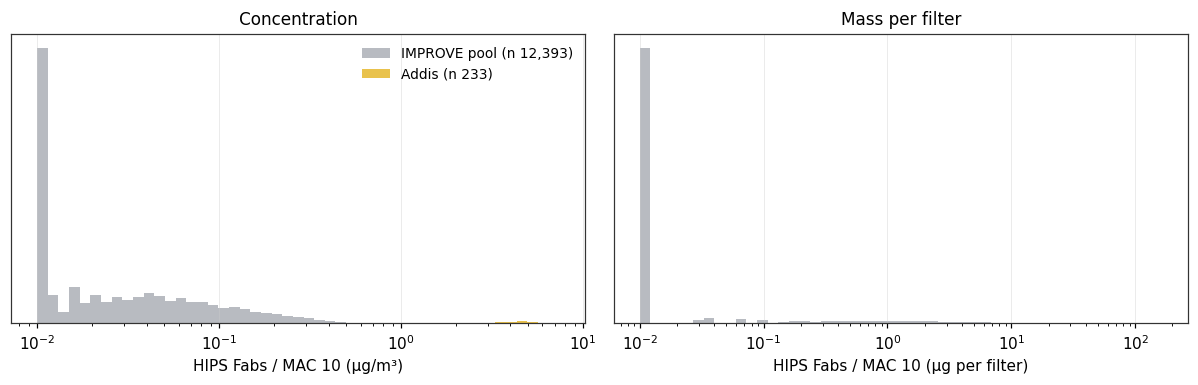

In [7]:
imp_mass = (refs.fabs_Mm1 / MAC_VALUE * refs.tor_volume_m3).dropna()
imp_tor = refs.y.dropna()
ad_mass = (addis_eval.Fabs / MAC_VALUE * addis_eval.Volume_m3).dropna()
ad_conc = (addis_eval.Fabs / MAC_VALUE).dropna()
imp_conc = (refs.fabs_Mm1 / MAC_VALUE).dropna()
pct = lambda ref, v: 100 * (ref < v).mean()
rows = []
for name, imp, ad in [('HIPS Fabs/10, µg/m³', imp_conc, ad_conc), ('HIPS Fabs/10 × volume, µg per filter', imp_mass, ad_mass)]:
    rows.append({'measure': name, 'IMPROVE median': imp.median(), 'IMPROVE p95': imp.quantile(.95), 'IMPROVE p99': imp.quantile(.99),
                 'Addis median': ad.median(), 'Addis median, IMPROVE percentile': pct(imp, ad.median()),
                 '% of Addis above IMPROVE p99': 100 * (ad > imp.quantile(.99)).mean()})
mass_tbl = pd.DataFrame(rows).set_index('measure')
display(mass_tbl.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (imp, ad, lab) in zip(axes, [(imp_conc, ad_conc, 'HIPS Fabs / MAC 10 (µg/m³)'), (imp_mass, ad_mass, 'HIPS Fabs / MAC 10 (µg per filter)')]):
    bins = np.geomspace(max(0.01, min(imp.quantile(.005), ad.min())), max(imp.max(), ad.max()), 50)
    ax.hist(imp.clip(bins[0], bins[-1]), bins, color='#8a8f98', alpha=.6, density=True, label=f'IMPROVE pool (n {len(imp):,})')
    ax.hist(ad.clip(bins[0], bins[-1]), bins, color='#e0a800', alpha=.7, density=True, label=f'Addis (n {len(ad)})')
    ax.set_xscale('log'); ax.set_xlabel(lab); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=9)
axes[0].set_title('Concentration', fontsize=11); axes[1].set_title('Mass per filter', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / 'mass_vs_concentration.png', dpi=200); plt.show()

In [8]:
c, m = mass_tbl.iloc[0], mass_tbl.iloc[1]
display(Markdown(f'''**Answer: still an extrapolation in mass, but a far smaller one.** The Addis median is
{c['Addis median'] / c['IMPROVE median']:.0f}x the IMPROVE median in µg/m³ but {m['Addis median'] / m['IMPROVE median']:.0f}x in µg per filter, and
{c['Addis median'] / c['IMPROVE p99']:.1f}x vs {m['Addis median'] / m['IMPROVE p99']:.1f}x the IMPROVE 99th percentile. {m['% of Addis above IMPROVE p99']:.0f} % of Addis filters
are still above IMPROVE's 99th percentile in mass (all of them in concentration), so the calibration sees few
filters as heavily loaded as Addis. The gallery's three-crossplot section now has a **Units: µg per filter** switch.'''))

**Answer: still an extrapolation in mass, but a far smaller one.** The Addis median is
41x the IMPROVE median in µg/m³ but 9x in µg per filter, and
5.4x vs 1.2x the IMPROVE 99th percentile. 78 % of Addis filters
are still above IMPROVE's 99th percentile in mass (all of them in concentration), so the calibration sees few
filters as heavily loaded as Addis. The gallery's three-crossplot section now has a **Units: µg per filter** switch.

## 4. The hump near 1000-1300 cm⁻¹ in the Addis spectra

Two checks on the VIBES-corrected spectra (the only baseline that reaches below 1425 cm⁻¹):
- **Where is the excess?** Median spectra, each filter scaled by its CH band (2800-3000 cm⁻¹) so loading
  drops out, Addis by season against the IMPROVE pool.
- **What does it track?** Within Addis, band areas per m³ against SPARTAN chemistry (Spearman ρ).
  Reference positions: sulfate ν3 ~1100 and ν4 ~615 cm⁻¹, ammonium ~1415, silicate Si-O ~1000-1080,
  PTFE C-F ~1150 and ~1210 cm⁻¹.

Filter dataset loaded: 44493 measurements
Sites: ['CHTS' 'ETAD' 'INDH' 'USPA']
Date range: 2013-06-28 to 2024-12-08


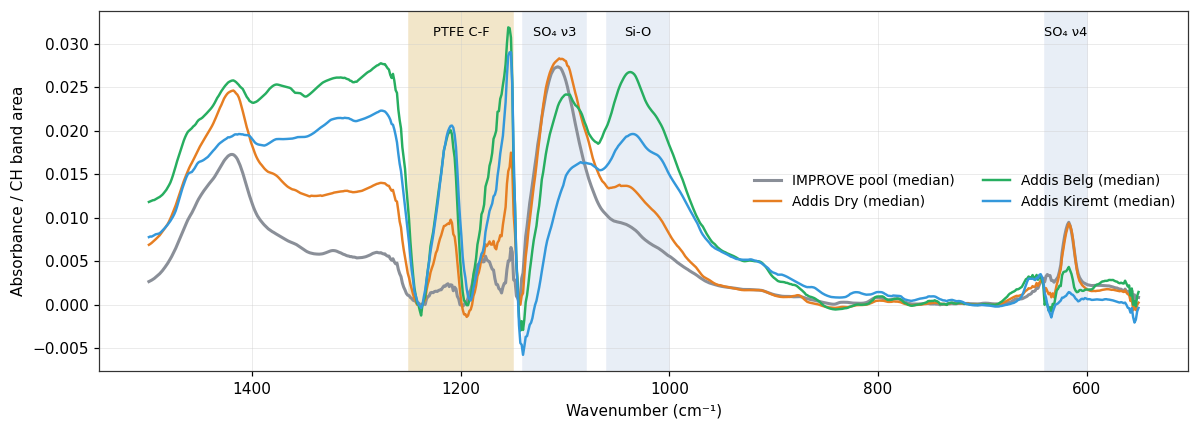

Largest Addis-minus-IMPROVE excess between 850 and 1300 cm⁻¹: 1153 cm⁻¹


CH-normalised median peak, sulfate 1080-1120 cm⁻¹: Addis 0.0230, IMPROVE 0.0273


CH-normalised median peak, PTFE 1140-1170 cm⁻¹:    Addis 0.0246, IMPROVE 0.0066


In [9]:
ctx, _ = load_context()
m = 'VIBES-full-r70'
wn = np.asarray(ctx.wn_by[m]); XA = np.asarray(ctx.XA[m]); X = np.asarray(ctx.X[m])
ch = (wn >= 2800) & (wn <= 3000)
norm = lambda Z: Z / np.abs(Z[:, ch].sum(1, keepdims=True))
win = (wn >= 550) & (wn <= 1500)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(wn[win], np.median(norm(X), 0)[win], color='#8a8f98', lw=2, label='IMPROVE pool (median)')
for g in SEASONS:
    take = ctx.addis.season.eq(g).to_numpy()
    ax.plot(wn[win], np.median(norm(XA[take]), 0)[win], color=SEASON_COLORS[g], lw=1.6, label=f'Addis {g.split()[0]} (median)')
for x0, x1, lab in [(1150, 1250, 'PTFE C-F'), (1000, 1060, 'Si-O'), (1080, 1140, 'SO₄ ν3'), (600, 640, 'SO₄ ν4')]:
    ax.axvspan(x0, x1, color='#f2e6c9' if lab == 'PTFE C-F' else '#e8eef6', zorder=0)
    ax.text((x0 + x1) / 2, ax.get_ylim()[1] * 0.95, lab, ha='center', va='top', fontsize=8.5)
ax.invert_xaxis(); ax.set_xlabel('Wavenumber (cm⁻¹)'); ax.set_ylabel('Absorbance / CH band area')
ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout(); fig.savefig(FIG / 'addis_vs_improve_low_wavenumber.png', dpi=200); plt.show()

excess = np.median(norm(XA), 0) - np.median(norm(X), 0)
band_win = (wn >= 850) & (wn <= 1300)
peak = float(wn[np.argmax(np.where(band_win, excess, -np.inf))])
print(f'Largest Addis-minus-IMPROVE excess between 850 and 1300 cm⁻¹: {peak:.0f} cm⁻¹')
near = lambda Z, lo, hi: float(np.median(norm(Z), 0)[(wn >= lo) & (wn <= hi)].max())
print(f'CH-normalised median peak, sulfate 1080-1120 cm⁻¹: Addis {near(XA, 1080, 1120):.4f}, IMPROVE {near(X, 1080, 1120):.4f}')
print(f'CH-normalised median peak, PTFE 1140-1170 cm⁻¹:    Addis {near(XA, 1140, 1170):.4f}, IMPROVE {near(X, 1140, 1170):.4f}')

In [10]:
CHEM = {'ChemSpec_Sulfate_Ion_PM2.5': 'sulfate', 'ChemSpec_Ammonium_Ion_PM2.5': 'ammonium',
        'ChemSpec_Silicon_PM2.5': 'Si', 'ChemSpec_Aluminum_PM2.5': 'Al', 'ChemSpec_Calcium_PM2.5': 'Ca',
        'ChemSpec_Potassium_Ion_PM2.5': 'K⁺', 'ChemSpec_Nitrate_Ion_PM2.5': 'nitrate'}
f = load_filter_data()
e = f.loc[f.Site.eq('ETAD') & f.Parameter.isin(CHEM)]
wide = e.pivot_table(index='FilterId', columns='Parameter', values='Concentration', aggfunc='mean').rename(columns=CHEM)
# SPARTAN chemistry is keyed by cartridge (ETAD-0001); the PTFE filter is ETAD-0001-1
cart = ctx.addis.ExternalFilterId.astype(str).str.rsplit('-', n=1).str[0].reset_index(drop=True)
chem = pd.DataFrame({'cartridge': cart}).merge(wide, left_on='cartridge', right_index=True, how='left')
vol = ctx.addis.Volume_m3.to_numpy(float)
BANDS = {'SO₄ ν4 600-640': (600, 640), 'Si-O 1000-1060': (1000, 1060), 'SO₄ ν3 1080-1140': (1080, 1140),
         'PTFE 1150-1250': (1150, 1250), 'NH₄⁺ 1400-1430': (1400, 1430), 'CH 2800-3000': (2800, 3000)}
area = pd.DataFrame({b: XA[:, (wn >= lo) & (wn <= hi)].sum(1) / vol for b, (lo, hi) in BANDS.items()})
rho = pd.DataFrame({c: [spearmanr(*area[[b]].join(chem[[c]]).dropna().T.values).statistic for b in BANDS] for c in CHEM.values()}, index=list(BANDS))
rho.to_csv(FIG / 'band_chemistry_spearman.csv')
display(Markdown(f'Spearman ρ, band area per m³ vs SPARTAN chemistry (µg/m³), {int(chem.sulfate.notna().sum())} Addis filters with sulfate'))
display(rho.round(2).style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1))

Filter dataset loaded: 44493 measurements
Sites: ['CHTS' 'ETAD' 'INDH' 'USPA']
Date range: 2013-06-28 to 2024-12-08


Spearman ρ, band area per m³ vs SPARTAN chemistry (µg/m³), 186 Addis filters with sulfate

,sulfate,ammonium,Si,Al,Ca,K⁺,nitrate
SO₄ ν4 600-640,0.530000,0.650000,-0.030000,-0.070000,0.150000,-0.210000,-0.320000
Si-O 1000-1060,0.390000,0.160000,0.900000,0.920000,0.660000,0.540000,0.430000
SO₄ ν3 1080-1140,0.720000,0.780000,0.380000,0.360000,0.470000,0.030000,-0.170000
PTFE 1150-1250,0.160000,-0.080000,0.350000,0.390000,0.100000,0.620000,0.250000
NH₄⁺ 1400-1430,0.670000,0.570000,0.470000,0.480000,0.320000,0.530000,0.120000
CH 2800-3000,0.720000,0.600000,0.430000,0.440000,0.240000,0.510000,-0.010000


In [11]:
sio = {g: near(XA[ctx.addis.season.eq(g).to_numpy()], 1000, 1060) for g in SEASONS}
sio_imp = near(X, 1000, 1060)
display(Markdown(f'''**Answer: the broad hump near 1000 cm⁻¹ is silicate dust (Si-O), not sulfate.**
- Its maximum sits near **1035 cm⁻¹**, and relative to CH it is {sio['Belg (Mar-May)'] / sio_imp:.1f}x the IMPROVE level in Belg,
  {sio['Kiremt (Jun-Sep)'] / sio_imp:.1f}x in Kiremt and {sio['Dry (Oct-Feb)'] / sio_imp:.1f}x in Dry. Within Addis the 1000-1060 band tracks
  **Si (ρ {rho.loc['Si-O 1000-1060', 'Si']:.2f}) and Al ({rho.loc['Si-O 1000-1060', 'Al']:.2f})**.
- The **sulfate** band (~1100 cm⁻¹) tracks sulfate ({rho.loc['SO₄ ν3 1080-1140', 'sulfate']:.2f}) and ammonium ({rho.loc['SO₄ ν3 1080-1140', 'ammonium']:.2f}),
  but relative to CH it is no stronger in Addis than in IMPROVE ({near(XA, 1080, 1120):.4f} vs {near(X, 1080, 1120):.4f}).
- Separately, sharp **PTFE** features at ~1153 and ~1210 cm⁻¹ are {near(XA, 1140, 1170) / near(X, 1140, 1170):.1f}x IMPROVE: filter-substrate
  signal the VIBES background leaves on Addis filters (consistent with the Blanks tab: held-out ETAD blanks correct
  12-15x worse than IMPROVE, mostly in the PTFE band).
- Addis is also higher than IMPROVE across 1250-1450 cm⁻¹ (nitrate, ammonium and carbonate absorb there); not tested here.
- Caveats: dust is not obviously the EC driver (the 7 Oct within-season groupings split by dust, not by HIPS EC), and
  dropping the PTFE window from VIBES calibrations on 8 Oct did **not** reduce the Addis intercept. These features
  explain what the Addis spectra look like; they have not yet been shown to explain the EC bias.'''))

**Answer: the broad hump near 1000 cm⁻¹ is silicate dust (Si-O), not sulfate.**
- Its maximum sits near **1035 cm⁻¹**, and relative to CH it is 2.6x the IMPROVE level in Belg,
  1.9x in Kiremt and 1.4x in Dry. Within Addis the 1000-1060 band tracks
  **Si (ρ 0.90) and Al (0.92)**.
- The **sulfate** band (~1100 cm⁻¹) tracks sulfate (0.72) and ammonium (0.78),
  but relative to CH it is no stronger in Addis than in IMPROVE (0.0230 vs 0.0273).
- Separately, sharp **PTFE** features at ~1153 and ~1210 cm⁻¹ are 3.7x IMPROVE: filter-substrate
  signal the VIBES background leaves on Addis filters (consistent with the Blanks tab: held-out ETAD blanks correct
  12-15x worse than IMPROVE, mostly in the PTFE band).
- Addis is also higher than IMPROVE across 1250-1450 cm⁻¹ (nitrate, ammonium and carbonate absorb there); not tested here.
- Caveats: dust is not obviously the EC driver (the 7 Oct within-season groupings split by dust, not by HIPS EC), and
  dropping the PTFE window from VIBES calibrations on 8 Oct did **not** reduce the Addis intercept. These features
  explain what the Addis spectra look like; they have not yet been shown to explain the EC bias.

## Still open from the meeting

- **Chemical speciation side by side** (Ann): the local IMPROVE cache has EC, OC, Fe, soil and mass but no
  sulfate. A sulfate comparison against the IMPROVE analogs needs an IMPROVE sulfate pull (FED / IMPROVE portal).
- **Boundary-layer normalisation of Addis concentrations**: needs boundary-layer heights; start from Kian's
  paper (or Sina) for the source, ERA5 `boundary_layer_height` is the usual fallback.
- **Chile sites** (Talca, Santiago in SPARTAN; the IMPROVE Chile sites): after AAAR, per Ann.
- **Show all held-out filters**: done in the gallery (Meeting › Three crossplots, *IMPROVE filters: All held-out IMPROVE*).
